# Prediksi PM2.5 Harian Jakarta, Januari–Maret 2026

**Datavidia 11 · Warmup** · Target: indeks AQI PM2.5 (US EPA) · Metrik: MAE · Horizon: 90 hari

Notebook ini menjawab satu pertanyaan: **dengan data sampai 31 Desember 2025, berapa indeks PM2.5 Jakarta setiap hari pada 1 Januari sampai 31 Maret 2026?**

Alur pengerjaannya:

1. Memahami batasan soal dan memeriksa kualitas data.
2. Mencari pola yang masih bisa dipakai 90 hari ke depan.
3. Membuat validasi yang meniru kondisi lomba.
4. Membandingkan baseline dan beberapa model.
5. Melatih model versi 1 dan membuat submission.
6. Menguji apakah MAE di bawah 15 mungkin dicapai, lalu membuat model versi 2.

## 1. Persiapan

Notebook hanya memakai `numpy` dan `pandas`. Grafik dibuat sebagai SVG, jadi tidak perlu memasang pustaka tambahan. Folder data dicari otomatis, baik saat dijalankan di komputer lokal maupun di Kaggle.

In [1]:
from html import escape
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import SVG, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")


def find_data_dir() -> Path:
    candidates = [Path("data"), Path("../data"), Path(".")]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates += [path.parent for path in kaggle_input.rglob("train.csv")]
    for folder in candidates:
        if (folder / "train.csv").exists() and (folder / "test.csv").exists():
            return folder
    raise FileNotFoundError("train.csv dan test.csv tidak ditemukan.")


DATA_DIR = find_data_dir()
SUBMISSION_DIR = Path("submission")
SUBMISSION_DIR.mkdir(exist_ok=True)
OUTPUT_PATH = SUBMISSION_DIR / "submission_1.csv"
OUTPUT_V2_PATH = SUBMISSION_DIR / "submission_2.csv"
ORIGIN_GAP_DAYS = 3
HOLIDAY_GROUPS = ["Idul Fitri", "Imlek", "Nyepi"]
HOLIDAY_SHRINK = 10

print(f"numpy {np.__version__} | pandas {pd.__version__}")

numpy 2.3.5 | pandas 2.3.3


In [ ]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS, WASH = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE = "#2a78d6", "#eb6834"
FONT = 'system-ui, -apple-system, "Segoe UI", sans-serif'
MONTHS = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]


def to_x(index) -> np.ndarray:
    return np.array([pd.Timestamp(day).toordinal() for day in index], dtype=float)


def nice_ticks(low: float, high: float, count: int = 5) -> np.ndarray:
    span = max(high - low, 1e-9)
    base = 10 ** np.floor(np.log10(span / count))
    step = next(base * m for m in (1, 2, 2.5, 5, 10) if span / (base * m) <= count)
    return np.arange(np.floor(low / step) * step, np.ceil(high / step) * step + step / 2, step)


def text(x, y, value, size=11, fill=MUTED, anchor="start", weight=400) -> str:
    return (
        f'<text x="{x:.1f}" y="{y:.1f}" font-size="{size}" fill="{fill}" text-anchor="{anchor}" '
        f'font-weight="{weight}" font-family=\'{FONT}\'>{escape(str(value))}</text>'
    )


def line_panel(series, x_ticks, title, subtitle="", width=920, height=340, y_range=None, shade=None, right=16):
    """Menggambar satu panel garis. Nilai NaN menjadi celah pada garis."""
    left, top, bottom = 44, 88, height - 30
    plot_right = width - right
    all_x = np.concatenate([np.asarray(item["x"], dtype=float) for item in series])
    values = [np.asarray(item["y"], dtype=float) for item in series]
    values += [np.asarray(item[key], dtype=float) for item in series for key in ("low", "high") if key in item]
    all_y = np.concatenate(values)
    y_low, y_high = y_range or (min(0, np.nanmin(all_y)), np.nanmax(all_y))
    ticks = nice_ticks(y_low, y_high)
    y_low, y_high = ticks[0], ticks[-1]
    x_low, x_high = np.nanmin(all_x), np.nanmax(all_x)
    sx = lambda v: left + (np.asarray(v, dtype=float) - x_low) / max(x_high - x_low, 1e-9) * (plot_right - left)
    sy = lambda v: bottom - (np.asarray(v, dtype=float) - y_low) / (y_high - y_low) * (bottom - top)

    parts = [text(0, 18, title, 15, INK, weight=600)]
    if subtitle:
        parts.append(text(0, 38, subtitle, 12, INK_2))

    for start, end, label in shade or []:
        x0, x1 = float(sx(max(start, x_low))), float(sx(min(end, x_high)))
        parts.append(f'<rect x="{x0:.1f}" y="{top}" width="{max(x1 - x0, 1):.1f}" height="{bottom - top}" fill="{WASH}"/>')
        if label:
            parts.append(text(x0 + 6, top + 15, label, 11, INK_2))

    for tick in ticks:
        py = float(sy(tick))
        color = AXIS if abs(tick) < 1e-9 or tick == ticks[0] else GRID
        parts.append(f'<line x1="{left}" x2="{plot_right}" y1="{py:.1f}" y2="{py:.1f}" stroke="{color}" stroke-width="1"/>')
        label = f"{tick:.2f}".rstrip("0").rstrip(".")
        parts.append(text(left - 7, py + 4, label, 11, MUTED, "end"))
    for tick, label in x_ticks:
        if x_low <= tick <= x_high:
            parts.append(text(float(sx(tick)), bottom + 19, label, 11, MUTED, "middle"))

    legend_x = 0.0
    for item in series:
        if not item.get("label"):
            continue
        parts.append(
            f'<line x1="{legend_x:.1f}" x2="{legend_x + 18:.1f}" y1="60" y2="60" '
            f'stroke="{item["color"]}" stroke-width="{max(item.get("width", 2), 2)}" stroke-linecap="round"/>'
        )
        parts.append(text(legend_x + 24, 64, item["label"], 12, INK_2))
        legend_x += 38 + len(item["label"]) * 6.6

    for item in series:
        x, y = np.asarray(item["x"], dtype=float), np.asarray(item["y"], dtype=float)
        if "low" in item:
            px, lo, hi = sx(x), sy(item["low"]), sy(item["high"])
            points = list(zip(px, hi)) + list(zip(px[::-1], lo[::-1]))
            path = " ".join(f"{a:.1f},{b:.1f}" for a, b in points)
            parts.append(f'<polygon points="{path}" fill="{item["color"]}" fill-opacity="0.16"/>')
        valid = ~np.isnan(y)
        breaks = np.flatnonzero(np.diff(valid.astype(int)))
        for segment in np.split(np.arange(len(y)), breaks + 1):
            if not valid[segment[0]]:
                continue
            path = " ".join(f"{a:.1f},{b:.1f}" for a, b in zip(sx(x[segment]), sy(y[segment])))
            parts.append(
                f'<polyline points="{path}" fill="none" stroke="{item["color"]}" '
                f'stroke-width="{item.get("width", 2)}" stroke-linejoin="round" stroke-linecap="round"/>'
            )
        for px, py, tip in zip(sx(x), sy(y), item.get("tips", [])):
            if np.isfinite(py):
                parts.append(f'<circle cx="{px:.1f}" cy="{py:.1f}" r="6" fill="transparent"><title>{escape(tip)}</title></circle>')
    return "".join(parts)


def show_chart(panels, width=920, height=340, columns=1):
    """Menampilkan satu panel atau beberapa panel kecil dalam satu SVG."""
    panel_width = (width - 24 * (columns - 1)) / columns
    rows = int(np.ceil(len(panels) / columns))
    body = ""
    for number, panel in enumerate(panels):
        x, y = (number % columns) * (panel_width + 24), (number // columns) * (height + 12)
        body += f'<svg x="{x:.1f}" y="{y:.1f}" width="{panel_width:.1f}" height="{height}" overflow="visible">{panel(panel_width, height)}</svg>'
    total = rows * height + (rows - 1) * 12
    display(SVG(data=(
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width + 24}" height="{total + 24}" '
        f'viewBox="-12 -12 {width + 24} {total + 24}" style="max-width:100%;height:auto;background:{SURFACE}">'
        f'<rect x="-12" y="-12" width="{width + 24}" height="{total + 24}" fill="{SURFACE}"/>{body}</svg>'
    )))

## 2. Memuat dan memeriksa data

Sebelum modeling, ada tiga hal yang perlu dipastikan: tanggalnya lengkap, target yang kosong ada di mana, dan data apa yang benar-benar tersedia saat memprediksi.

In [ ]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["tanggal"]).set_index("tanggal").sort_index()
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["tanggal"])
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
ispu = pd.read_csv(DATA_DIR / "ispu_jakarta.csv", parse_dates=["tanggal"])
cams = pd.read_csv(DATA_DIR / "cams_kualitas_udara.csv", parse_dates=["tanggal"]).set_index("tanggal")
y = train["pm25"]

assert train.index.is_unique and (train.index.to_series().diff().dropna().dt.days == 1).all()
assert len(test) == 90 and test["id"].equals(sample["id"])

pd.DataFrame(
    [
        ("train", len(train), train.index.min().date(), train.index.max().date(), "target, cuaca, kalender"),
        ("test", len(test), test["tanggal"].min().date(), test["tanggal"].max().date(), "kalender saja"),
        ("ispu", len(ispu), ispu["tanggal"].min().date(), ispu["tanggal"].max().date(), "tidak ada di periode tes"),
        ("cams", len(cams), cams.index.min().date(), cams.index.max().date(), "tidak ada di periode tes"),
    ],
    columns=["file", "baris", "mulai", "selesai", "isi"],
)

,file,baris,mulai,selesai,isi
0,train,1826,2021-01-01,2025-12-31,"target, cuaca, kalender"
1,test,90,2026-01-01,2026-03-31,kalender saja
2,ispu,4165,2021-01-01,2025-11-30,tidak ada di periode tes
3,cams,1246,2022-08-04,2025-12-31,tidak ada di periode tes


In [4]:
missing = y.isna()
run_id = (missing != missing.shift()).cumsum()[missing]
gaps = (
    y[missing].index.to_series().groupby(run_id)
    .agg(mulai="min", selesai="max", jumlah_hari="size")
    .sort_values("jumlah_hari", ascending=False)
    .reset_index(drop=True)
)
print(f"Target kosong: {missing.sum()} dari {len(y)} hari ({missing.mean():.1%})")
gaps.head(5)

Target kosong: 394 dari 1826 hari (21.6%)


,mulai,selesai,jumlah_hari
0,2021-01-25,2022-01-26,367
1,2024-12-10,2024-12-15,6
2,2023-02-24,2023-02-26,3
3,2022-02-12,2022-02-14,3
4,2025-12-29,2025-12-31,3


**Yang perlu dicatat:**

- Tanggal di `train` lengkap dan tidak ada duplikat.
- Target kosong hampir setahun penuh, dari 25 Januari 2021 sampai 26 Januari 2022. Baris ini **tidak diisi** untuk melatih model final, karena nilai perkiraan bisa mengubah pola musiman.
- Tiga hari terakhir sebelum periode tes (29–31 Desember 2025) juga kosong. Validasi nanti harus meniru kondisi ini.
- Cuaca, ISPU, dan CAMS tidak ada di periode tes, sehingga tidak bisa langsung menjadi fitur prediksi.

## 3. Mencari pola yang bisa dipakai

Karena yang tersedia di masa depan hanya kalender, pertanyaan utamanya adalah: **seberapa banyak PM2.5 bisa dijelaskan oleh tanggal?**

### 3.1 Pola jangka panjang

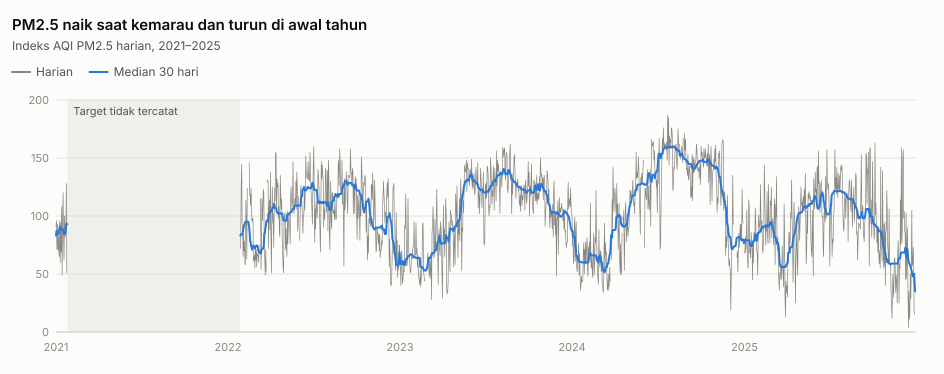

In [5]:
smooth = y.rolling(30, center=True, min_periods=15).median()
year_ticks = [(pd.Timestamp(f"{year}-01-01").toordinal(), str(year)) for year in range(2021, 2027)]
x_all = to_x(y.index)

show_chart([
    lambda w, h: line_panel(
        [
            {"x": x_all, "y": y.values, "color": MUTED, "width": 0.7, "label": "Harian"},
            {"x": x_all, "y": smooth.values, "color": BLUE, "width": 2, "label": "Median 30 hari"},
        ],
        year_ticks,
        "PM2.5 naik saat kemarau dan turun di awal tahun",
        "Indeks AQI PM2.5 harian, 2021–2025",
        w, h,
        shade=[(pd.Timestamp("2021-01-25").toordinal(), pd.Timestamp("2022-01-26").toordinal(), "Target tidak tercatat")],
    )
], height=350)

### 3.2 Pola musiman per bulan

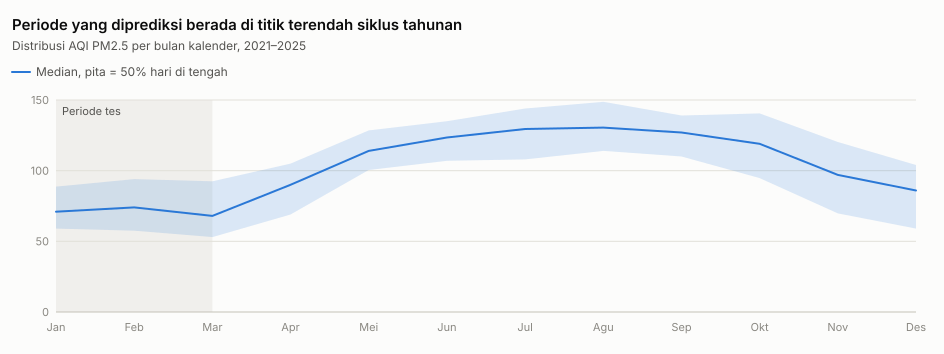

,hari_tercatat,median,q25,q75
Jan–Mar,,,,
2021,24,88.50,69.00,96.00
2022,58,84.00,66.00,114.00
2023,87,65.00,53.00,76.50
2024,89,63.00,50.00,77.00
2025,90,79.00,68.00,95.75


In [6]:
monthly = y.groupby(y.index.month).quantile([0.25, 0.5, 0.75]).unstack()
monthly.columns = ["q25", "median", "q75"]
month_x = monthly.index.values.astype(float)

show_chart([
    lambda w, h: line_panel(
        [{"x": month_x, "y": monthly["median"], "low": monthly["q25"], "high": monthly["q75"], "color": BLUE, "label": "Median, pita = 50% hari di tengah"}],
        [(number + 1, name) for number, name in enumerate(MONTHS)],
        "Periode yang diprediksi berada di titik terendah siklus tahunan",
        "Distribusi AQI PM2.5 per bulan kalender, 2021–2025",
        w, h, y_range=(0, float(monthly["q75"].max())),
        shade=[(1, 3, "Periode tes")],
    )
], height=330)

jfm = y[y.index.month <= 3]
pd.DataFrame({
    "hari_tercatat": jfm.groupby(jfm.index.year).count(),
    "median": jfm.groupby(jfm.index.year).median(),
    "q25": jfm.groupby(jfm.index.year).quantile(0.25),
    "q75": jfm.groupby(jfm.index.year).quantile(0.75),
}).rename_axis("Jan–Mar")

Januari–Maret konsisten menjadi periode rendah, tetapi mediannya berbeda antartahun, dari 63 sampai 88,5. Jadi musim memberi **bentuk** yang andal, sedangkan **level** tiap tahun tetap menjadi sumber ketidakpastian.

### 3.3 Seberapa lama informasi hari ini bertahan?

Korelasi mentah bisa menipu karena ikut mengandung pola musim. Misalnya, korelasi pada jeda 180 hari negatif hanya karena kemarau berhadapan dengan musim hujan. Untuk melihat ingatan yang sebenarnya, musim dibuang dulu dengan mengurangi median bulanan, lalu **anomali** yang tersisa diukur.

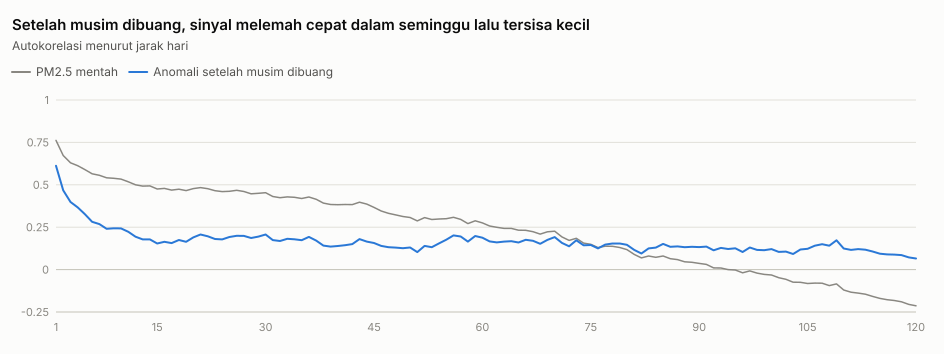

,PM2.5 mentah,Anomali
1 hari,0.76,0.61
7 hari,0.56,0.27
30 hari,0.45,0.21
60 hari,0.28,0.19
90 hari,0.04,0.13


In [7]:
anomaly = y - y.groupby(y.index.month).transform("median")
lags = np.arange(1, 121)
raw_acf = np.array([y.autocorr(int(lag)) for lag in lags])
anomaly_acf = np.array([anomaly.autocorr(int(lag)) for lag in lags])

show_chart([
    lambda w, h: line_panel(
        [
            {"x": lags, "y": raw_acf, "color": MUTED, "width": 1.5, "label": "PM2.5 mentah"},
            {"x": lags, "y": anomaly_acf, "color": BLUE, "width": 2, "label": "Anomali setelah musim dibuang"},
        ],
        [(lag, str(lag)) for lag in (1, 15, 30, 45, 60, 75, 90, 105, 120)],
        "Setelah musim dibuang, sinyal melemah cepat dalam seminggu lalu tersisa kecil",
        "Autokorelasi menurut jarak hari",
        w, h, y_range=(min(raw_acf.min(), anomaly_acf.min()), 1),
    )
], height=330)

pd.DataFrame(
    {"PM2.5 mentah": raw_acf[[0, 6, 29, 59, 89]], "Anomali": anomaly_acf[[0, 6, 29, 59, 89]]},
    index=[f"{lag} hari" for lag in (1, 7, 30, 60, 90)],
)

Korelasi anomali turun dari 0,61 (1 hari) ke 0,27 (7 hari), lalu tersisa 0,13 pada 90 hari. Artinya, kejadian harian cepat hilang, tetapi **level suatu periode masih sedikit terbawa**. Sisa kecil inilah yang nanti diuji lewat varian "anomali".

### 3.4 Efek hari libur

Hari libur adalah satu-satunya informasi non-musim yang tersedia di periode tes. Efeknya diukur sebagai selisih terhadap median 29 hari di sekitarnya, supaya pengaruh musim tidak ikut terhitung.

In [8]:
def holiday_group(names: pd.Series) -> pd.Series:
    names = names.fillna("")
    groups = pd.Series("", index=names.index)
    for group in HOLIDAY_GROUPS:
        groups[names.str.contains(group)] = group
    return groups


train_groups = holiday_group(train["nama_libur"])
future_groups = pd.Series(holiday_group(test["nama_libur"]).values, index=pd.DatetimeIndex(test["tanggal"]))
calendar_groups = pd.concat([train_groups, future_groups])

local_residual = (y - y.rolling(29, center=True, min_periods=12).median()).dropna()
effect_table = pd.DataFrame(
    [
        {
            "kelompok": group,
            "hari_contoh": int((train_groups.reindex(local_residual.index) == group).sum()),
            "efek_median": local_residual[train_groups.reindex(local_residual.index) == group].median(),
        }
        for group in HOLIDAY_GROUPS
    ]
)
effect_table["efek_setelah_dikecilkan"] = (
    effect_table["efek_median"] * effect_table["hari_contoh"] / (effect_table["hari_contoh"] + HOLIDAY_SHRINK)
)
display(effect_table)
test.loc[future_groups.values != "", ["tanggal", "nama_libur"]].assign(kelompok=future_groups[future_groups != ""].values)

,kelompok,hari_contoh,efek_median,efek_setelah_dikecilkan
0,Idul Fitri,25,-14.50,-10.36
1,Imlek,7,-11.00,-4.53
2,Nyepi,7,-18.00,-7.41


,tanggal,nama_libur,kelompok
46,2026-02-16,Cuti Bersama Imlek,Imlek
47,2026-02-17,Tahun Baru Imlek,Imlek
76,2026-03-18,Cuti Bersama Nyepi,Nyepi
77,2026-03-19,Hari Suci Nyepi,Nyepi
78,2026-03-20,Cuti Bersama Idul Fitri,Idul Fitri
79,2026-03-21,Idul Fitri,Idul Fitri
80,2026-03-22,Idul Fitri (hari kedua),Idul Fitri
81,2026-03-23,Cuti Bersama Idul Fitri,Idul Fitri
82,2026-03-24,Cuti Bersama Idul Fitri,Idul Fitri


Contoh setiap kelompok libur sedikit, sehingga efeknya **dikecilkan** dengan faktor $n / (n + 10)$. Semakin sedikit contohnya, semakin kecil koreksi yang dipercaya.

### 3.5 Data pendukung

ISPU dan CAMS berkorelasi dengan target, tetapi tidak tersedia untuk 2026. Satu-satunya cara memakainya adalah **mengisi target yang kosong di masa lalu**. Ide ini diuji di bagian 5.

In [9]:
ispu_daily = ispu.groupby("tanggal")["pm25"].median()
support = {"ISPU PM2.5": ispu_daily, "CAMS us_aqi": cams["us_aqi"]}
rows = []
for name, values in support.items():
    pair = pd.concat([y, values.rename("x")], axis=1).dropna()
    rows.append({
        "sumber": name,
        "hari_beririsan": len(pair),
        "korelasi_spearman": pair["pm25"].rank().corr(pair["x"].rank()),
        "median_sumber": pair["x"].median(),
        "median_target": pair["pm25"].median(),
    })
pd.DataFrame(rows)

,sumber,hari_beririsan,korelasi_spearman,median_sumber,median_target
0,ISPU PM2.5,716,0.75,82.50,105.00
1,CAMS us_aqi,1225,0.64,161.00,105.00


## 4. Validasi yang meniru kondisi lomba

Split acak **tidak boleh** dipakai di sini, karena model akan melihat hari sesudah tanggal yang diprediksinya. Aku memakai dua jenis uji mundur:

| Uji | Cara | Fungsi |
|---|---|---|
| **Jan–Mar** | Latih sampai akhir Desember, prediksi Jan–Mar 2023, 2024, 2025 | Paling mirip dengan soal |
| **Rolling** | 34 titik awal bulanan, masing-masing prediksi 90 hari | Mengecek model tetap stabil di musim lain |

Pada setiap uji, 3 hari terakhir sebelum periode prediksi dibuang, karena di data asli 29–31 Desember 2025 juga kosong. Skor hanya dihitung pada tanggal yang targetnya tercatat, sama seperti aturan lomba.

In [10]:
JFM_FOLDS = {year: pd.date_range(f"{year}-01-01", f"{year}-03-31") for year in (2023, 2024, 2025)}
ROLLING_FOLDS = [pd.date_range(start, periods=90) for start in pd.date_range("2023-01-01", "2025-10-01", freq="MS")]


def history_before(dates: pd.DatetimeIndex) -> pd.Series:
    return y[y.index < dates[0] - pd.Timedelta(days=ORIGIN_GAP_DAYS)]


def fold_errors(model, dates: pd.DatetimeIndex) -> pd.Series:
    actual = y.reindex(dates)
    prediction = pd.Series(model(history_before(dates), dates), index=dates)
    return (actual - prediction).abs().dropna()


def evaluate(models: dict) -> pd.DataFrame:
    rows = []
    for name, model in models.items():
        jfm_scores = {f"Jan–Mar {year}": fold_errors(model, dates).mean() for year, dates in JFM_FOLDS.items()}
        rolling_errors = [fold_errors(model, dates) for dates in ROLLING_FOLDS]
        holiday_errors = pd.concat([e[calendar_groups.reindex(e.index).fillna("") != ""] for e in rolling_errors])
        rows.append({
            "model": name,
            **jfm_scores,
            "rata2 Jan–Mar": np.mean(list(jfm_scores.values())),
            "terburuk": max(jfm_scores.values()),
            "rolling": np.mean([e.mean() for e in rolling_errors]),
            "hari libur": holiday_errors.mean(),
        })
    return pd.DataFrame(rows).set_index("model")

## 5. Membandingkan model

### 5.1 Baseline

Baseline adalah batas bawah. Model yang lebih rumit harus bisa mengalahkannya.

In [11]:
baselines = {
    "Konstanta 104 (sample)": lambda h, d: np.full(len(d), 104.0),
    "Median seluruh histori": lambda h, d: np.full(len(d), h.median()),
    "Median 28 hari terakhir": lambda h, d: np.full(len(d), h.dropna().iloc[-28:].median()),
    "Nilai tahun lalu": lambda h, d: h.reindex(d - pd.DateOffset(years=1)).fillna(h.median()).values,
}
baseline_results = evaluate(baselines)
baseline_results

,Jan–Mar 2023,Jan–Mar 2024,Jan–Mar 2025,rata2 Jan–Mar,terburuk,rolling,hari libur
model,,,,,,,
Konstanta 104 (sample),37.79,39.81,28.78,35.46,39.81,29.13,38.82
Median seluruh histori,37.79,41.54,32.04,37.13,41.54,30.24,39.07
Median 28 hari terakhir,24.19,38.12,19.90,27.40,38.12,29.47,29.04
Nilai tahun lalu,34.94,26.67,28.74,30.12,34.94,29.76,40.57


### 5.2 Model musiman

Karena metriknya MAE, nilai terbaik untuk ditebak adalah **median**, bukan rata-rata. Maka kurva musiman dilatih dengan regresi median:

$$\hat y(t) = \beta_0 + \sum_{j=1}^{K}\left[a_j \sin\!\left(\frac{2\pi j\,t}{365.25}\right) + b_j \cos\!\left(\frac{2\pi j\,t}{365.25}\right)\right]$$

Di sini $t$ adalah urutan hari dalam setahun. Nilai $K=1$ berarti satu gelombang tahunan dengan hanya 3 parameter. Parameter sedikit penting karena data target hanya sekitar empat tahun.

Model tambahan yang diuji:

- **Libur:** menambahkan efek libur yang sudah dikecilkan.
- **Hari:** menambahkan efek Senin sampai Minggu.
- **Anomali:** meneruskan sebagian penyimpangan 56 hari terakhir, lalu meluruh.
- **Isi ISPU:** mengisi target kosong dari ISPU sebelum melatih kurva.

In [12]:
def design_matrix(dates: pd.DatetimeIndex, harmonics: int = 1) -> np.ndarray:
    angle = 2 * np.pi * dates.dayofyear.values / 365.25
    columns = [np.ones(len(angle))]
    for order in range(1, harmonics + 1):
        columns += [np.sin(order * angle), np.cos(order * angle)]
    return np.column_stack(columns)


def fit_median_curve(history: pd.Series, harmonics: int = 1, iterations: int = 60) -> np.ndarray:
    """Regresi L1 dengan iteratively reweighted least squares."""
    history = history.dropna()
    X = design_matrix(history.index, harmonics)
    target = history.values
    weights = np.ones(len(target))
    ridge = 1e-3 * np.eye(X.shape[1])
    for _ in range(iterations):
        beta = np.linalg.solve((X.T * weights) @ X + ridge, (X.T * weights) @ target)
        weights = 1 / np.maximum(np.abs(target - X @ beta), 1.0)
    return beta


def median_curve(history, dates, harmonics=1):
    return design_matrix(dates, harmonics) @ fit_median_curve(history, harmonics)


def seasonal_window(history, dates, window=30):
    history = history.dropna()
    doy, values = history.index.dayofyear.values, history.values
    predictions = []
    for day in dates.dayofyear.values:
        distance = np.abs(doy - min(day, 365))
        nearby = values[np.minimum(distance, 365 - distance) <= window]
        predictions.append(np.median(nearby if len(nearby) else values))
    return np.array(predictions)


def holiday_effect(history, dates):
    residual = (history - history.rolling(29, center=True, min_periods=12).median()).dropna()
    groups = train_groups.reindex(residual.index)
    future = calendar_groups.reindex(dates).fillna("").values
    effect = np.zeros(len(dates))
    for group in HOLIDAY_GROUPS:
        values = residual[groups == group]
        if len(values):
            effect[future == group] = values.median() * len(values) / (len(values) + HOLIDAY_SHRINK)
    return effect


def weekday_effect(history, dates):
    residual = (history - history.rolling(29, center=True, min_periods=12).median()).dropna()
    return residual.groupby(residual.index.dayofweek).median().reindex(dates.dayofweek).fillna(0).values


def recent_anomaly(history, dates, weight=0.25, lookback=56, decay=60):
    recent = history.dropna().iloc[-lookback:]
    older = history[history.index < recent.index.min() - pd.Timedelta(days=60)].dropna()
    if len(older) < 180:
        return np.zeros(len(dates))
    level = np.median(recent.values - seasonal_window(older, recent.index))
    return weight * level * np.exp(-np.arange(1, len(dates) + 1) / decay)


def fill_from_ispu(history):
    """Pemetaan ISPU ke AQI hanya dipelajari dari data sebelum titik prediksi."""
    source = ispu_daily.reindex(history.index)
    overlap = history.notna() & source.notna()
    if overlap.sum() < 60:
        return history
    X = np.column_stack([np.ones(overlap.sum()), source[overlap].values])
    target = history[overlap].values
    weights = np.ones(len(target))
    for _ in range(40):
        beta = np.linalg.solve((X.T * weights) @ X + 1e-6 * np.eye(2), (X.T * weights) @ target)
        weights = 1 / np.maximum(np.abs(target - X @ beta), 1.0)
    filled = history.copy()
    gap = history.isna() & source.notna()
    filled[gap] = np.clip(beta[0] + beta[1] * source[gap], 0, 500)
    return filled


def final_model(history, dates):
    return median_curve(history, dates, 1) + holiday_effect(history, dates)


candidates = {
    "Jendela musiman ±30 hari": seasonal_window,
    "Kurva K=1": lambda h, d: median_curve(h, d, 1),
    "Kurva K=2": lambda h, d: median_curve(h, d, 2),
    "Kurva K=3": lambda h, d: median_curve(h, d, 3),
    "Kurva K=1 + libur": final_model,
    "Kurva K=1 + libur + hari": lambda h, d: final_model(h, d) + weekday_effect(h, d),
    "Kurva K=1 + libur + anomali": lambda h, d: final_model(h, d) + recent_anomaly(h, d),
    "Kurva K=1 (isi ISPU) + libur": lambda h, d: median_curve(fill_from_ispu(h), d, 1) + holiday_effect(h, d),
}
candidate_results = evaluate(candidates)
candidate_results

,Jan–Mar 2023,Jan–Mar 2024,Jan–Mar 2025,rata2 Jan–Mar,terburuk,rolling,hari libur
model,,,,,,,
Jendela musiman ±30 hari,24.20,18.04,23.52,21.92,24.20,22.74,25.91
Kurva K=1,22.97,19.51,22.68,21.72,22.97,22.15,23.61
Kurva K=2,24.54,17.64,24.86,22.35,24.86,22.29,24.65
Kurva K=3,25.01,17.66,24.62,22.43,25.01,22.78,24.09
Kurva K=1 + libur,22.95,19.51,22.49,21.65,22.95,22.09,21.60
Kurva K=1 + libur + hari,23.80,19.59,22.63,22.01,23.80,22.14,21.29
Kurva K=1 + libur + anomali,22.16,20.22,22.41,21.60,22.41,21.67,22.24
Kurva K=1 (isi ISPU) + libur,21.72,21.55,21.24,21.50,21.72,23.59,23.64


### 5.3 Memilih model

Aturan pemilihannya: **ambil model paling sederhana, kecuali tambahan memberi perbaikan yang jelas.** Selisih kecil pada tiga periode uji belum tentu nyata.

- **Semua model musiman mengalahkan baseline.** MAE Jan–Mar sekitar 21,5–22,4, sedangkan baseline terbaik 27,40.
- **Kurva K=1 dipilih.** K=2 dan K=3 lebih rumit, tetapi skor Jan–Mar dan rolling-nya lebih buruk.
- **Koreksi libur dipakai.** MAE pada hari libur turun dari 23,61 ke 21,60 tanpa merusak skor keseluruhan.
- **Efek hari dibuang.** MAE Jan–Mar justru naik dari 21,65 ke 22,01.
- **Pengisian dari ISPU dibuang.** Jan–Mar hanya membaik 0,15, tetapi rolling memburuk dari 22,09 ke 23,59.
- **Varian anomali diuji lebih lanjut** di bagian 5.4, karena skornya paling dekat.

Tabel berikut membandingkan model terpilih dengan baseline terbaik.

In [13]:
final_name = "Kurva K=1 + libur"
reference = baseline_results.loc["Median 28 hari terakhir"]
chosen = candidate_results.loc[final_name]
pd.DataFrame({
    "Median 28 hari": reference[["rata2 Jan–Mar", "terburuk", "rolling"]],
    final_name: chosen[["rata2 Jan–Mar", "terburuk", "rolling"]],
    "selisih": chosen[["rata2 Jan–Mar", "terburuk", "rolling"]] - reference[["rata2 Jan–Mar", "terburuk", "rolling"]],
})

,Median 28 hari,Kurva K=1 + libur,selisih
rata2 Jan–Mar,27.40,21.65,-5.76
terburuk,38.12,22.95,-15.18
rolling,29.47,22.09,-7.38


### 5.4 Menguji pesaing terdekat

Varian **anomali** punya skor rolling lebih baik, jadi perlu dicek apakah hasil itu kebetulan dari satu pengaturan parameter. Caranya: bandingkan per titik rolling, lalu ulangi pada 8 pengaturan bobot, panjang jendela, dan laju peluruhan.

In [14]:
challenger = lambda h, d: final_model(h, d) + recent_anomaly(h, d)
final_scores = np.array([fold_errors(final_model, dates).mean() for dates in ROLLING_FOLDS])
challenger_scores = np.array([fold_errors(challenger, dates).mean() for dates in ROLLING_FOLDS])
shift = recent_anomaly(y, pd.DatetimeIndex(test["tanggal"]))

print(f"Varian anomali lebih baik di {(challenger_scores < final_scores).sum()} dari {len(final_scores)} titik rolling")
print(f"Efeknya pada prediksi 2026: {shift[0]:.1f} di awal Januari, {shift[-1]:.1f} di akhir Maret, rata-rata {shift.mean():.1f}")

sensitivity = []
for weight in (0.25, 0.5):
    for lookback in (28, 56):
        for decay in (30, 60):
            variant = lambda h, d: final_model(h, d) + recent_anomaly(h, d, weight, lookback, decay)
            sensitivity.append({
                "bobot": weight,
                "jendela": lookback,
                "peluruhan": decay,
                "rata2 Jan–Mar": np.mean([fold_errors(variant, dates).mean() for dates in JFM_FOLDS.values()]),
                "rolling": np.mean([fold_errors(variant, dates).mean() for dates in ROLLING_FOLDS]),
            })
sensitivity = pd.DataFrame(sensitivity)
sensitivity["selisih Jan–Mar"] = sensitivity["rata2 Jan–Mar"] - chosen["rata2 Jan–Mar"]
sensitivity["selisih rolling"] = sensitivity["rolling"] - chosen["rolling"]
sensitivity

Varian anomali lebih baik di 23 dari 34 titik rolling
Efeknya pada prediksi 2026: -11.0 di awal Januari, -2.5 di akhir Maret, rata-rata -5.7


,bobot,jendela,peluruhan,rata2 Jan–Mar,rolling,selisih Jan–Mar,selisih rolling
0,0.25,28,30,21.97,21.78,0.32,-0.31
1,0.25,28,60,22.26,21.62,0.61,-0.47
2,0.25,56,30,21.60,21.83,-0.05,-0.27
3,0.25,56,60,21.60,21.67,-0.05,-0.42
4,0.50,28,30,22.36,21.59,0.71,-0.50
5,0.50,28,60,23.01,21.35,1.36,-0.74
6,0.50,56,30,21.57,21.65,-0.08,-0.44
7,0.50,56,60,21.57,21.41,-0.08,-0.69


**Keputusan: model versi 1 tetap Kurva K=1 + libur.**

- Varian anomali memang lebih baik pada rolling, di 23 dari 34 titik dan pada semua 8 pengaturan. Jadi sinyalnya kemungkinan nyata.
- Namun pada Januari–Maret, periode yang paling mirip soal, perbaikannya paling besar hanya 0,08. Dengan jendela 28 hari, skornya malah lebih buruk sampai 1,36.
- Karena manfaatnya belum terbukti di periode target, varian ini tidak dijadikan model utama. Ini adalah **eksperimen pertama yang layak dicoba di leaderboard**, karena akan menurunkan prediksi rata-rata 5,7 poin.

## 6. Membedah model final

### 6.1 Apa yang dipelajari model

In [15]:
beta = fit_median_curve(y)
amplitude = np.hypot(beta[1], beta[2])
peak_angle = np.arctan2(beta[1], beta[2]) % (2 * np.pi)
peak_day = int(round(peak_angle / (2 * np.pi) * 365.25))
low_day = int(round((peak_day + 365.25 / 2) % 365.25))
to_date = lambda day: (pd.Timestamp("2025-01-01") + pd.Timedelta(days=day - 1)).strftime("%d %b")

pd.Series({
    "Level tengah tahunan": f"{beta[0]:.1f}",
    "Amplitudo musim": f"±{amplitude:.1f}",
    "Puncak kurva": to_date(peak_day),
    "Titik terendah kurva": to_date(low_day),
}, name="nilai").to_frame()

,nilai
Level tengah tahunan,102.6
Amplitudo musim,±32.7
Puncak kurva,08 Aug
Titik terendah kurva,06 Feb


### 6.2 Hasil uji mundur Januari–Maret

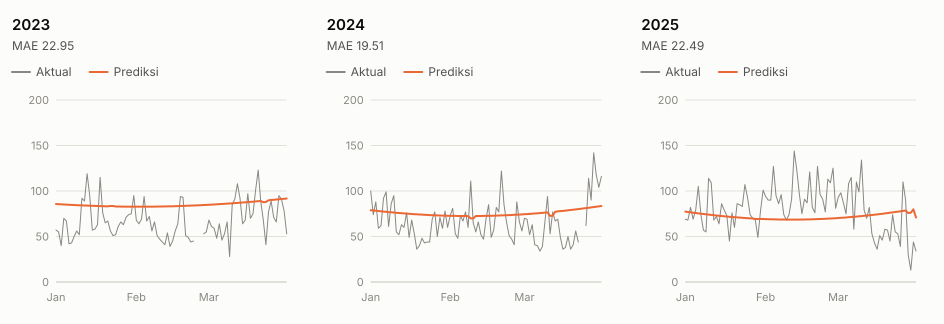

,hari_dinilai,MAE,bias
periode,,,
Jan–Mar 2023,87.00,22.95,17.79
Jan–Mar 2024,89.00,19.51,8.94
Jan–Mar 2025,90.00,22.49,-8.42
Rata-rata,88.67,21.65,6.10


In [16]:
def backtest_panel(year, dates):
    actual = y.reindex(dates)
    prediction = final_model(history_before(dates), dates)
    ticks = [(pd.Timestamp(f"{year}-{month:02d}-01").toordinal(), MONTHS[month - 1]) for month in (1, 2, 3)]
    mae = (actual - prediction).abs().mean()
    return lambda w, h: line_panel(
        [
            {"x": to_x(dates), "y": actual.values, "color": MUTED, "width": 1, "label": "Aktual"},
            {"x": to_x(dates), "y": prediction, "color": ORANGE, "width": 2, "label": "Prediksi"},
        ],
        ticks, f"{year}", f"MAE {mae:.2f}", w, h, y_range=(0, 160),
    )


show_chart([backtest_panel(year, dates) for year, dates in JFM_FOLDS.items()], height=300, columns=3)

fold_rows = []
for year, dates in JFM_FOLDS.items():
    actual = y.reindex(dates)
    prediction = pd.Series(final_model(history_before(dates), dates), index=dates)
    error = (prediction - actual).dropna()
    fold_rows.append({"periode": f"Jan–Mar {year}", "hari_dinilai": len(error), "MAE": error.abs().mean(), "bias": error.mean()})
fold_table = pd.DataFrame(fold_rows).set_index("periode")
fold_table.loc["Rata-rata"] = [fold_table["hari_dinilai"].mean(), fold_table["MAE"].mean(), fold_table["bias"].mean()]
fold_table

**Cara membacanya:**

- MAE stabil di 19,51–22,95 pada tiga tahun yang berbeda.
- Bias berubah tanda: prediksi terlalu tinggi pada 2023 dan 2024, lalu terlalu rendah pada 2025. Ini menunjukkan level tiap tahun memang sulit ditebak dari kalender saja.
- Garis prediksi halus karena lonjakan harian tidak bisa diketahui 90 hari sebelumnya. Untuk MAE, menebak level tengah lebih aman daripada mengejar lonjakan.

## 7. Prediksi versi 1 dan submission

Setelah model dipilih, model dilatih ulang memakai **seluruh** data sampai 31 Desember 2025.

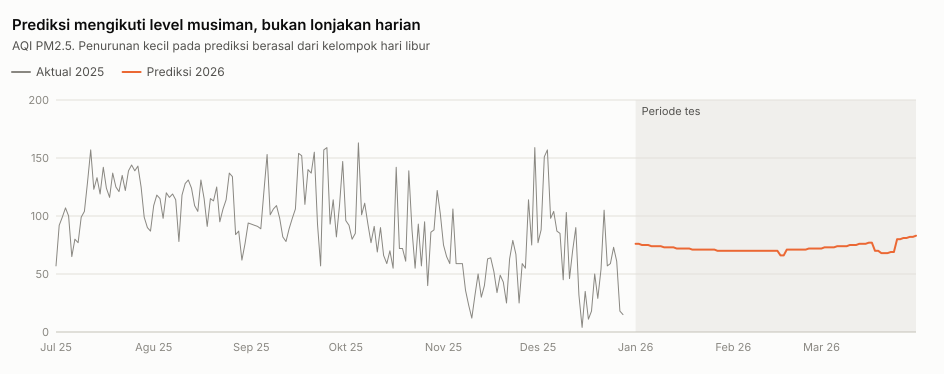

,mean,min,max
bulan,,,
2026-01,72.35,70,76
2026-02,70.25,66,72
2026-03,74.77,68,83


In [17]:
future_dates = pd.DatetimeIndex(test["tanggal"])
forecast = final_model(y, future_dates)
submission = pd.DataFrame({"id": test["id"], "pm25": np.clip(np.rint(forecast), 0, 500).astype(int)})
submission = sample[["id"]].merge(submission, on="id", how="left", validate="one_to_one")

history_view = y["2025-07-01":]
tick_dates = pd.date_range("2025-07-01", "2026-03-01", freq="MS")
tips = [f"{day.date()}: {value}" for day, value in zip(future_dates, submission["pm25"])]

show_chart([
    lambda w, h: line_panel(
        [
            {"x": to_x(history_view.index), "y": history_view.values, "color": MUTED, "width": 1, "label": "Aktual 2025"},
            {"x": to_x(future_dates), "y": submission["pm25"].values.astype(float), "color": ORANGE, "width": 2, "label": "Prediksi 2026", "tips": tips},
        ],
        [(day.toordinal(), f"{MONTHS[day.month - 1]} {str(day.year)[2:]}") for day in tick_dates],
        "Prediksi mengikuti level musiman, bukan lonjakan harian",
        "AQI PM2.5. Penurunan kecil pada prediksi berasal dari kelompok hari libur",
        w, h, y_range=(0, float(np.nanmax(history_view))),
        shade=[(future_dates[0].toordinal(), future_dates[-1].toordinal(), "Periode tes")],
    )
], height=350)

monthly_forecast = submission.groupby(submission["id"].str[:7])["pm25"].agg(["mean", "min", "max"])
monthly_forecast.index.name = "bulan"
monthly_forecast

In [18]:
submission.to_csv(OUTPUT_PATH, index=False)
saved = pd.read_csv(OUTPUT_PATH)

assert list(saved.columns) == list(sample.columns)
assert saved["id"].equals(sample["id"])
assert len(saved) == 90 and saved["id"].is_unique
assert saved["pm25"].notna().all() and saved["pm25"].between(0, 500).all()

print(f"{OUTPUT_PATH.as_posix()} tersimpan: {len(saved)} baris, prediksi {saved['pm25'].min()}–{saved['pm25'].max()}")
saved.head()

submission/submission_1.csv tersimpan: 90 baris, prediksi 66–83


,id,pm25
0,2026-01-01,76
1,2026-01-02,76
2,2026-01-03,75
3,2026-01-04,75
4,2026-01-05,75


## 8. Analisis lanjutan: bisakah MAE di bawah 15?

Bagian ini menguji target MAE di bawah 15 dengan tiga pertanyaan:

1. Berapa skor terbaik yang mungkin, seandainya sebagian jawaban diketahui?
2. Apakah ada sinyal yang belum terpakai?
3. Apakah model yang lebih kuat benar-benar lebih baik saat diuji tanpa melihat masa depan?

### 8.1 Batas skor terbaik

Tabel berikut memberi model "contekan" yang mustahil dimiliki saat lomba. Kalau model yang tahu sebagian jawaban saja belum mencapai 15, model biasa tidak bisa diharapkan mencapainya.

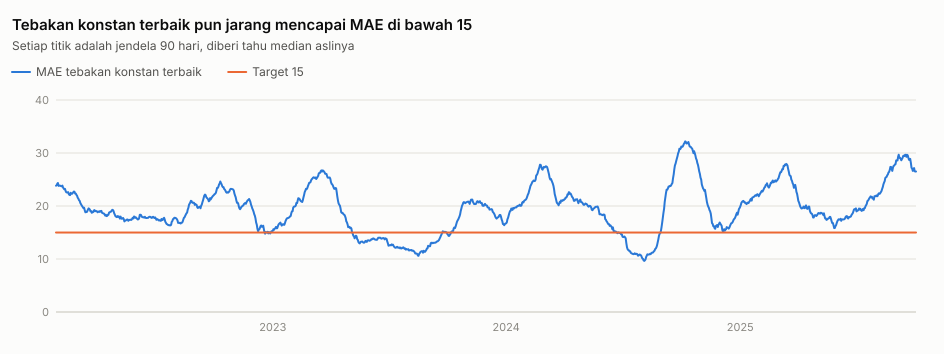

Jendela 90 hari dengan MAE konstan terbaik < 15: 16.2%
Khusus yang mulai sekitar 1 Januari (±15 hari): 4.2%
Oktober–Desember 2025, tebakan konstan terbaik: 26.55


,Jan–Mar 2023,Jan–Mar 2024,Jan–Mar 2025,rata-rata
Model v1,22.95,19.51,22.49,21.65
Tahu median seluruh periode,15.30,17.12,19.87,17.43
Tahu median tiap bulan,14.39,16.92,17.62,16.31
Tahu nilai asli kemarin,14.98,17.38,19.67,17.34
Tahu median tiap 2 minggu,13.09,13.72,14.31,13.71


In [19]:
def block_floor(values: pd.Series, freq: str) -> float:
    return (values - values.groupby(pd.Grouper(freq=freq)).transform("median")).abs().mean()


floor_rows = {}
for year, dates in JFM_FOLDS.items():
    actual = y.reindex(dates).dropna()
    prediction = pd.Series(final_model(history_before(dates), dates), index=dates)
    floor_rows[f"Jan–Mar {year}"] = {
        "Model v1": (actual - prediction[actual.index]).abs().mean(),
        "Tahu median seluruh periode": (actual - actual.median()).abs().mean(),
        "Tahu median tiap bulan": block_floor(actual, "MS"),
        "Tahu nilai asli kemarin": (actual - y.shift(1).reindex(actual.index)).abs().mean(),
        "Tahu median tiap 2 minggu": block_floor(actual, "14D"),
    }
floor_table = pd.DataFrame(floor_rows)
floor_table["rata-rata"] = floor_table.mean(axis=1)

window_rows = []
for start in pd.date_range("2022-01-27", "2025-10-03", freq="D"):
    window = y.reindex(pd.date_range(start, periods=90)).dropna()
    if len(window) >= 70:
        window_rows.append((start, (window - window.median()).abs().mean()))
constant_floor = pd.DataFrame(window_rows, columns=["mulai", "mae"]).set_index("mulai")["mae"]
near_new_year = constant_floor[
    ((constant_floor.index.month == 12) & (constant_floor.index.day >= 15))
    | ((constant_floor.index.month == 1) & (constant_floor.index.day <= 15))
]
latest = y["2025-10-01":"2025-12-31"].dropna()

show_chart([
    lambda w, h: line_panel(
        [
            {"x": to_x(constant_floor.index), "y": constant_floor.values, "color": BLUE, "width": 2, "label": "MAE tebakan konstan terbaik"},
            {"x": to_x(constant_floor.index), "y": np.full(len(constant_floor), 15.0), "color": ORANGE, "width": 2, "label": "Target 15"},
        ],
        [(pd.Timestamp(f"{year}-01-01").toordinal(), str(year)) for year in range(2022, 2026)],
        "Tebakan konstan terbaik pun jarang mencapai MAE di bawah 15",
        "Setiap titik adalah jendela 90 hari, diberi tahu median aslinya",
        w, h, y_range=(0, float(constant_floor.max())),
    )
], height=330)

print(f"Jendela 90 hari dengan MAE konstan terbaik < 15: {(constant_floor < 15).mean():.1%}")
print(f"Khusus yang mulai sekitar 1 Januari (±15 hari): {(near_new_year < 15).mean():.1%}")
print(f"Oktober–Desember 2025, tebakan konstan terbaik: {(latest - latest.median()).abs().mean():.2f}")
floor_table

**Cara membacanya:** walaupun median asli Januari–Maret diketahui, MAE masih sekitar 17,4. Bahkan memakai nilai asli kemarin untuk setiap hari, yang mustahil pada prediksi 90 hari, MAE masih sekitar 17,3. Angka di bawah 15 baru muncul kalau naik-turun tiap dua minggu diketahui, padahal itu bergantung pada cuaca yang belum terjadi.

### 8.2 Sinyal baru: level akhir 2025 turun

Pada November 2025 target jauh lebih rendah dari tahun-tahun sebelumnya. Sebelum dipakai, perlu dicek apakah ini kondisi udara yang nyata atau hanya gangguan sensor target. ISPU berasal dari stasiun yang berbeda, jadi bisa dipakai sebagai pembanding.

In [20]:
CURVES = [
    (1, None, False), (1, 730, False), (1, 365, False), (1, None, True),
    (1, 730, True), (2, None, False), (2, 730, False),
]
LOOKBACKS = (28, 56, 90, 120)
WEIGHTS = (0.25, 0.5, 0.75, 1.0)
DECAYS = (30, 60, 120, np.inf)
MODES = ("add", "mult")


def predict_curve(history, dates, harmonics=1, half_life=None, log_scale=False):
    """Kurva median dengan opsi bobot data terbaru dan skala log."""
    history = history.dropna()
    X = design_matrix(history.index, harmonics)
    target = np.log1p(history.values) if log_scale else history.values
    prior = np.ones(len(target))
    if half_life:
        prior = 0.5 ** ((history.index.max() - history.index).days.values / half_life)
    weights = prior.copy()
    ridge = 1e-3 * np.eye(X.shape[1])
    for _ in range(60):
        beta = np.linalg.solve((X.T * weights) @ X + ridge, (X.T * weights) @ target)
        weights = prior / np.maximum(np.abs(target - X @ beta), 1.0)
    prediction = design_matrix(dates, harmonics) @ beta
    return np.expm1(prediction) if log_scale else prediction


def level_gap(history, lookback):
    observed = history.dropna()
    recent = observed.iloc[-lookback:]
    older = observed[observed.index < recent.index.min()]
    if len(older) < 120:
        return np.nan
    return float(np.median(recent.values - predict_curve(older, recent.index)))


november = pd.concat({"target": y, "ispu": ispu_daily, "cams": cams["us_aqi"]}, axis=1)
november = november[november.index.month == 11]
november_table = november.groupby(november.index.year).median()
november_table["target/ispu"] = november_table["target"] / november_table["ispu"]
display(november_table.rename_axis("November"))

persistence_rows = []
for origin in pd.date_range("2023-01-01", "2025-10-01", freq="7D"):
    dates = pd.date_range(origin, periods=90)
    history = history_before(dates)
    future = y.reindex(dates).dropna()
    if len(future) >= 60:
        expected = pd.Series(final_model(history, dates), index=dates)
        persistence_rows.append({
            "origin": origin,
            "galat_level": float((future - expected[future.index]).median()),
            "gap56": level_gap(history, 56),
            "gap90": level_gap(history, 90),
        })
persistence = pd.DataFrame(persistence_rows).set_index("origin")

summary = []
for lookback in (56, 90):
    gap = persistence[f"gap{lookback}"]
    current = level_gap(y, lookback)
    summary.append({
        "jendela": lookback,
        "selisih level saat ini": current,
        "paling rendah sebelumnya": gap.min(),
        "porsi yang biasanya bertahan": (persistence["galat_level"] * gap).sum() / (gap ** 2).sum(),
    })
pd.DataFrame(summary).set_index("jendela")

,target,ispu,cams,target/ispu
November,,,,
2021,NaN,61.00,NaN,NaN
2022,90.00,78.50,146.48,1.15
2023,105.50,80.00,170.81,1.32
2024,119.00,NaN,162.42,NaN
2025,59.00,55.00,133.92,1.07


,selisih level saat ini,paling rendah sebelumnya,porsi yang biasanya bertahan
jendela,,,
56,-39.01,-28.25,0.61
90,-38.47,-25.97,0.56


**Cara membacanya:**

- ISPU November 2025 berada di 55, padahal November 2022–2023 sekitar 80. Karena stasiun berbeda melihat penurunan yang sama, penurunan ini kemungkinan nyata.
- Selisih level saat ini lebih rendah daripada semua titik yang pernah terjadi di data validasi.
- Secara historis, lebih dari separuh selisih level biasanya masih terbawa ke 90 hari berikutnya. Namun, bisa juga musim hujan 2025 hanya datang lebih awal. Kalau begitu, level Januari–Maret bisa kembali normal.

### 8.3 Awas overfitting: 903 konfigurasi

Aku menguji 903 kombinasi kurva dan koreksi level. Memilih yang terbaik terlihat sangat menjanjikan, tetapi pemilihan itu melihat jawaban periode uji. Uji yang jujur adalah **nested walk-forward**: konfigurasi untuk setiap periode hanya boleh dipilih dari periode yang sudah selesai sebelumnya.

In [21]:
from itertools import product

CONFIGS = [(curve, 0, 0.0, 0.0, "none") for curve in CURVES] + [
    (curve, lookback, weight, decay, mode)
    for curve in CURVES
    for lookback, weight, decay, mode in product(LOOKBACKS, WEIGHTS, DECAYS, MODES)
]


def fold_parts(history, dates):
    observed = history.dropna()
    parts = {"holiday": holiday_effect(history, dates), "horizon": (dates - observed.index.max()).days.values.astype(float)}
    for curve in CURVES:
        parts[("base", curve)] = predict_curve(history, dates, *curve)
        for lookback in LOOKBACKS:
            recent = observed.iloc[-lookback:]
            older = observed[observed.index < recent.index.min()]
            if len(older) < 120:
                parts[("add", curve, lookback)] = parts[("mult", curve, lookback)] = 0.0
                continue
            expected = np.maximum(predict_curve(older, recent.index, *curve), 1.0)
            parts[("add", curve, lookback)] = float(np.median(recent.values - expected))
            parts[("mult", curve, lookback)] = float(np.median(np.log((recent.values + 1) / (expected + 1))))
    return parts


def config_prediction(parts, config):
    curve, lookback, weight, decay, mode = config
    prediction = parts[("base", curve)]
    if mode != "none":
        fade = weight * np.exp(-parts["horizon"] / decay)
        gap = parts[(mode, curve, lookback)]
        prediction = prediction + gap * fade if mode == "add" else prediction * np.exp(gap * fade)
    return np.clip(prediction + parts["holiday"], 0, 500)


def persistent_prediction(parts):
    return np.mean([config_prediction(parts, config) for config in CONFIGS], axis=0)


jfm_dates = list(JFM_FOLDS.values())
all_folds = jfm_dates + ROLLING_FOLDS
fold_cache = [fold_parts(history_before(dates), dates) for dates in all_folds]
fold_actual = [y.reindex(dates).values for dates in all_folds]
config_errors = np.array([
    [np.nanmean(np.abs(actual - config_prediction(parts, config))) for parts, actual in zip(fold_cache, fold_actual)]
    for config in CONFIGS
])

n_jfm = len(jfm_dates)
rolling_index = list(range(n_jfm, len(all_folds)))
starts = [dates[0] for dates in all_folds]


def nested_score(indices):
    scores = []
    for j in indices:
        past = [q for q in rolling_index if starts[q] + pd.Timedelta(days=90 + ORIGIN_GAP_DAYS) <= starts[j]]
        choice = int(np.argmin(config_errors[:, past].mean(axis=1))) if len(past) >= 6 else 0
        scores.append(config_errors[choice, j])
    return float(np.mean(scores))


best_on_test = int(np.argmin(config_errors[:, :n_jfm].mean(axis=1)))
pd.DataFrame(
    {
        "Jan–Mar": [config_errors[0, :n_jfm].mean(), config_errors[best_on_test, :n_jfm].mean(), nested_score(range(n_jfm))],
        "rolling": [config_errors[0, n_jfm:].mean(), config_errors[best_on_test, n_jfm:].mean(), nested_score(rolling_index)],
    },
    index=["Model v1", "Terbaik dari 903 (melihat jawaban)", "Dipilih tanpa melihat masa depan"],
)

,Jan–Mar,rolling
Model v1,21.65,22.09
Terbaik dari 903 (melihat jawaban),19.41,21.06
Dipilih tanpa melihat masa depan,23.70,21.76


Skor sekitar 19,4 hanya muncul karena konfigurasinya dipilih setelah melihat jawaban. Saat dipilih secara jujur, skor Januari–Maret justru memburuk menjadi sekitar 23,7. Karena itu, **tidak ada satu konfigurasi pun yang dipilih sebagai pemenang.**

### 8.4 Model yang lebih kompleks

Model berikut belajar dari ratusan titik waktu: regresi dengan fitur level, regresi dengan fitur cuaca dan CAMS, serta gradient boosting dengan loss MAE yang ditulis dengan NumPy. Semua fitur hanya memakai informasi yang tersedia sebelum titik prediksi.

In [22]:
EXOGENOUS = {
    "tmax": train["suhu_maks"], "tmin": train["suhu_min"], "uv": train["indeks_uv_maks"],
    "aod": cams["aerosol_optical_depth"], "cams": cams["us_aqi"],
}
H_MAX = 91


def series_gap(series, lookback):
    series = series.dropna()
    recent = series.iloc[-lookback:]
    older = series[series.index < recent.index.min()]
    if len(recent) < lookback * 0.6 or len(older) < 150:
        return 0.0
    return float(np.median(recent.values - predict_curve(older, recent.index)))


def origin_state(origin):
    history = y[y.index < origin - pd.Timedelta(days=ORIGIN_GAP_DAYS)]
    observed = history.dropna()
    features = {f"y{lookback}": series_gap(history, lookback) for lookback in (14, 28, 56, 90)}
    features["vol28"] = float(np.median(np.abs(observed.iloc[-28:] - observed.iloc[-28:].median())))
    for name, series in EXOGENOUS.items():
        for lookback in (28, 56):
            features[f"{name}{lookback}"] = series_gap(series[series.index < origin], lookback)
    joined = pd.concat([history, cams["us_aqi"]], axis=1).dropna()
    features["ratio56"] = 0.0
    if len(joined) > 200:
        log_ratio = np.log(joined.iloc[:, 0].clip(lower=1) / joined.iloc[:, 1].clip(lower=1))
        features["ratio56"] = float(log_ratio.iloc[-56:].median() - log_ratio.iloc[:-56].median())
    dates = pd.date_range(origin, periods=H_MAX)
    return features, predict_curve(history, dates), holiday_effect(history, dates), dates


def state_rows(state):
    features, base, holiday, dates = state
    angle = 2 * np.pi * dates.dayofyear.values / 365.25
    groups = calendar_groups.reindex(dates).fillna("").values
    fixed = np.tile([features[name] for name in features], (len(dates), 1))
    extra = np.column_stack([
        np.arange(1, len(dates) + 1), base, np.sin(angle), np.cos(angle),
        *[(groups == group).astype(float) for group in HOLIDAY_GROUPS], dates.dayofweek.values >= 5,
    ])
    return np.column_stack([fixed, extra])


class MedianGBM:
    """Gradient boosting kecil dengan loss MAE."""

    def __init__(self, n_trees, depth, min_leaf, seed, lr=0.04, bins=24, subsample=0.6, colsample=0.6):
        self.n_trees, self.depth, self.min_leaf, self.lr, self.bins = n_trees, depth, min_leaf, lr, bins
        self.subsample, self.colsample = subsample, colsample
        self.rng = np.random.default_rng(seed)

    def _bin(self, X):
        return np.column_stack([np.searchsorted(self.edges[j], X[:, j]) for j in range(X.shape[1])]).astype(np.int16)

    def _grow(self, binned, gradient, residual, index, level):
        if level < self.depth and len(index) >= 2 * self.min_leaf:
            total, count = gradient[index].sum(), len(index)
            best_gain, best_feature, best_bin = 1e-9, None, None
            for feature in self.rng.choice(binned.shape[1], max(1, int(self.colsample * binned.shape[1])), replace=False):
                column = binned[index, feature]
                left_sum = np.cumsum(np.bincount(column, weights=gradient[index], minlength=self.bins))[:-1]
                left_count = np.cumsum(np.bincount(column, minlength=self.bins))[:-1]
                valid = (left_count >= self.min_leaf) & (count - left_count >= self.min_leaf)
                if valid.any():
                    gain = left_sum**2 / np.maximum(left_count, 1) + (total - left_sum) ** 2 / np.maximum(count - left_count, 1) - total**2 / count
                    gain = np.where(valid, gain, -1)
                    split = int(np.argmax(gain))
                    if gain[split] > best_gain:
                        best_gain, best_feature, best_bin = gain[split], feature, split
            if best_feature is not None:
                mask = binned[index, best_feature] <= best_bin
                return (
                    best_feature, best_bin,
                    self._grow(binned, gradient, residual, index[mask], level + 1),
                    self._grow(binned, gradient, residual, index[~mask], level + 1),
                )
        return float(np.median(residual[index]))

    def _apply(self, node, binned, index, output):
        if not isinstance(node, tuple):
            output[index] = node
            return
        feature, split, left, right = node
        mask = binned[index, feature] <= split
        self._apply(left, binned, index[mask], output)
        self._apply(right, binned, index[~mask], output)

    def _tree_values(self, tree, binned):
        output = np.zeros(len(binned))
        self._apply(tree, binned, np.arange(len(binned)), output)
        return output

    def fit(self, X, target):
        self.edges = [np.unique(np.quantile(X[:, j], np.linspace(0, 1, self.bins + 1)[1:-1])) for j in range(X.shape[1])]
        binned = self._bin(X)
        self.start = float(np.median(target))
        current = np.full(len(target), self.start)
        self.trees = []
        for _ in range(self.n_trees):
            index = self.rng.choice(len(target), int(self.subsample * len(target)), replace=False)
            residual = target[index] - current[index]
            tree = self._grow(binned[index], np.sign(residual), residual, np.arange(len(index)), 0)
            self.trees.append(tree)
            current += self.lr * self._tree_values(tree, binned)
        return self

    def predict(self, X):
        binned = self._bin(X)
        return self.start + self.lr * sum(self._tree_values(tree, binned) for tree in self.trees)


origins = sorted(set(pd.date_range("2022-07-01", "2025-12-25", freq="7D")) | {dates[0] for dates in all_folds})
states = {origin: origin_state(origin) for origin in origins}
feature_names = list(states[origins[0]][0]) + ["h", "base", "sin", "cos", "hIF", "hIM", "hNY", "wknd"]
position = {name: i for i, name in enumerate(feature_names)}
X_all = np.vstack([state_rows(states[origin]) for origin in origins])
target_dates = np.concatenate([states[origin][3].values for origin in origins])
base_all = np.concatenate([states[origin][1] for origin in origins])
y_all = y.reindex(pd.DatetimeIndex(target_dates)).values
gbm_columns = [i for name, i in position.items() if name != "base"]


def linear_columns(X, names):
    horizon = X[:, position["h"]]
    columns = [X[:, position[name]] * np.exp(-horizon / tau) for name in names for tau in (30, 90, 1e9)]
    columns += [X[:, position[name]] for name in ("hIF", "hIM", "hNY")]
    return np.column_stack(columns)


def fit_linear(X, residual, names, ridge):
    columns = linear_columns(X, names)
    scale = columns.std(axis=0) + 1e-9
    columns = columns / scale
    weights = np.ones(len(residual))
    penalty = ridge * len(residual) * np.eye(columns.shape[1])
    for _ in range(25):
        beta = np.linalg.solve((columns.T * weights) @ columns + penalty * weights.mean(), (columns.T * weights) @ residual)
        weights = 1 / np.maximum(np.abs(residual - columns @ beta), 2.0)
    return lambda Z: (linear_columns(Z, names) / scale) @ beta


level_names = ["y56", "y90"]
exogenous_names = level_names + ["tmin56", "tmax56", "uv56", "aod56", "cams56", "ratio56"]
complex_models = {
    "Regresi fitur level": lambda Xt, r, Xq: fit_linear(Xt, r, level_names, 0.1)(Xq),
    "Regresi + cuaca & CAMS": lambda Xt, r, Xq: fit_linear(Xt, r, exogenous_names, 0.2)(Xq),
    "Gradient boosting depth 2": lambda Xt, r, Xq: np.mean([MedianGBM(100, 2, 500, seed).fit(Xt[:, gbm_columns], r).predict(Xq[:, gbm_columns]) for seed in range(3)], axis=0),
    "Gradient boosting depth 3": lambda Xt, r, Xq: np.mean([MedianGBM(120, 3, 700, seed).fit(Xt[:, gbm_columns], r).predict(Xq[:, gbm_columns]) for seed in range(3)], axis=0),
}

complex_errors = {name: [] for name in ["Model v1", *complex_models]}
for dates in all_folds:
    state = states[dates[0]]
    n_days = len(dates)
    X_query = state_rows(state)[:n_days]
    base, holiday = state[1][:n_days], state[2][:n_days]
    actual = y.reindex(dates).values
    cutoff = np.datetime64(dates[0] - pd.Timedelta(days=ORIGIN_GAP_DAYS))
    mask = (target_dates < cutoff) & ~np.isnan(y_all)
    complex_errors["Model v1"].append(np.nanmean(np.abs(actual - (base + holiday))))
    for name, model in complex_models.items():
        prediction = base + model(X_all[mask], y_all[mask] - base_all[mask], X_query) if mask.sum() >= 2500 else base + holiday
        complex_errors[name].append(np.nanmean(np.abs(actual - prediction)))

complex_errors = pd.DataFrame(complex_errors)
complex_table = complex_errors.iloc[:n_jfm].T
complex_table.columns = [f"Jan–Mar {year}" for year in JFM_FOLDS]
complex_table["rata2 Jan–Mar"] = complex_errors.iloc[:n_jfm].mean()
complex_table["rolling"] = complex_errors.iloc[n_jfm:].mean()
complex_table

,Jan–Mar 2023,Jan–Mar 2024,Jan–Mar 2025,rata2 Jan–Mar,rolling
Model v1,22.95,19.51,22.49,21.65,22.09
Regresi fitur level,22.95,22.14,21.33,22.14,21.63
Regresi + cuaca & CAMS,22.95,25.62,21.08,23.22,22.49
Gradient boosting depth 2,22.95,24.04,27.73,24.91,23.69
Gradient boosting depth 3,22.95,23.10,28.28,24.77,23.36


**Cara membacanya:** model yang lebih kompleks tidak mengalahkan versi 1 di Januari–Maret. Gradient boosting mendapat 24,77–24,91 dan regresi dengan cuaca serta CAMS mendapat 23,22. Regresi fitur level lebih baik pada rolling (21,63), tetapi lebih buruk di Januari–Maret (22,14). Data target yang hanya sekitar empat tahun belum cukup untuk model yang lebih rumit.

### 8.5 Model versi 2

Data belum bisa memastikan mana yang akan terjadi, jadi model versi 2 memakai **rata-rata dua skenario**:

- **Level kembali normal:** model versi 1.
- **Level rendah berlanjut:** rata-rata seluruh 903 konfigurasi, tanpa memilih pemenang.

Bobot 50:50 ditetapkan dari awal dan tidak dituning. Karena MAE bersifat konveks, MAE rata-rata dua prediksi tidak akan lebih buruk dari rata-rata MAE keduanya.

In [23]:
BLEND_WEIGHT = 0.5
blend_rows = {"v1: level normal": [], "Level berlanjut": [], "v2: blend 50:50": []}
for parts, actual in zip(fold_cache, fold_actual):
    normal = config_prediction(parts, CONFIGS[0])
    persistent = persistent_prediction(parts)
    blended = (1 - BLEND_WEIGHT) * normal + BLEND_WEIGHT * persistent
    for name, prediction in zip(blend_rows, (normal, persistent, blended)):
        blend_rows[name].append(np.nanmean(np.abs(actual - prediction)))
blend_errors = pd.DataFrame(blend_rows)

blend_table = blend_errors.iloc[:n_jfm].T
blend_table.columns = [f"Jan–Mar {year}" for year in JFM_FOLDS]
blend_table["rata2 Jan–Mar"] = blend_errors.iloc[:n_jfm].mean()
blend_table["terburuk"] = blend_errors.iloc[:n_jfm].max()
blend_table["rolling"] = blend_errors.iloc[n_jfm:].mean()
blend_table["menang vs v1"] = blend_errors.iloc[n_jfm:].lt(blend_errors["v1: level normal"].iloc[n_jfm:], axis=0).sum()
blend_table

,Jan–Mar 2023,Jan–Mar 2024,Jan–Mar 2025,rata2 Jan–Mar,terburuk,rolling,menang vs v1
v1: level normal,22.95,19.51,22.49,21.65,22.95,22.09,0
Level berlanjut,21.28,20.88,22.57,21.57,22.57,21.30,21
v2: blend 50:50,22.11,20.17,22.52,21.60,22.52,21.61,22


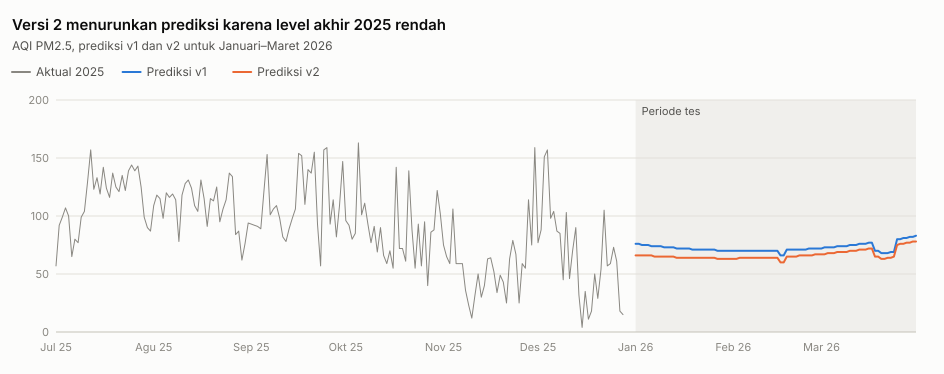

,MAE v1,MAE v2,lebih baik
median aktual,,,
50,25.38,21.75,v2
55,22.44,19.60,v2
60,20.13,18.05,v2
65,18.40,17.27,v2
70,17.42,17.60,v1
75,17.42,19.00,v1
80,18.52,21.40,v1
85,20.55,24.53,v1
90,23.50,28.28,v1


In [24]:
test_parts = fold_parts(y, future_dates)
normal_2026 = config_prediction(test_parts, CONFIGS[0])
persistent_2026 = persistent_prediction(test_parts)
blended_2026 = (1 - BLEND_WEIGHT) * normal_2026 + BLEND_WEIGHT * persistent_2026
submission_v2 = pd.DataFrame({"id": test["id"], "pm25": np.clip(np.rint(blended_2026), 0, 500).astype(int)})
submission_v2 = sample[["id"]].merge(submission_v2, on="id", how="left", validate="one_to_one")

show_chart([
    lambda w, h: line_panel(
        [
            {"x": to_x(history_view.index), "y": history_view.values, "color": MUTED, "width": 1, "label": "Aktual 2025"},
            {"x": to_x(future_dates), "y": submission["pm25"].values.astype(float), "color": BLUE, "width": 2, "label": "Prediksi v1"},
            {
                "x": to_x(future_dates), "y": submission_v2["pm25"].values.astype(float), "color": ORANGE, "width": 2, "label": "Prediksi v2",
                "tips": [f"{day.date()}: {value}" for day, value in zip(future_dates, submission_v2["pm25"])],
            },
        ],
        [(day.toordinal(), f"{MONTHS[day.month - 1]} {str(day.year)[2:]}") for day in tick_dates],
        "Versi 2 menurunkan prediksi karena level akhir 2025 rendah",
        "AQI PM2.5, prediksi v1 dan v2 untuk Januari–Maret 2026",
        w, h, y_range=(0, float(np.nanmax(history_view))),
        shade=[(future_dates[0].toordinal(), future_dates[-1].toordinal(), "Periode tes")],
    )
], height=350)

deviations = [
    (lambda values: (values - values.median()).values[:90])(y[f"{year}-01-01":f"{year}-03-31"].iloc[:90])
    for year in JFM_FOLDS
]
scenario_rows = []
for level in range(50, 95, 5):
    scenario_rows.append({
        "median aktual": level,
        "MAE v1": np.mean([np.nanmean(np.abs(level + dev - submission["pm25"].values[:len(dev)])) for dev in deviations]),
        "MAE v2": np.mean([np.nanmean(np.abs(level + dev - submission_v2["pm25"].values[:len(dev)])) for dev in deviations]),
    })
scenario_table = pd.DataFrame(scenario_rows).set_index("median aktual")
scenario_table["lebih baik"] = np.where(scenario_table["MAE v2"] < scenario_table["MAE v1"], "v2", "v1")
scenario_table

In [25]:
submission_v2.to_csv(OUTPUT_V2_PATH, index=False)
saved_v2 = pd.read_csv(OUTPUT_V2_PATH)

assert list(saved_v2.columns) == list(sample.columns)
assert saved_v2["id"].equals(sample["id"])
assert len(saved_v2) == 90 and saved_v2["id"].is_unique
assert saved_v2["pm25"].notna().all() and saved_v2["pm25"].between(0, 500).all()

print(f"{OUTPUT_V2_PATH.as_posix()} tersimpan: {len(saved_v2)} baris, prediksi {saved_v2['pm25'].min()}–{saved_v2['pm25'].max()}")
print(f"Rata-rata prediksi: v1 {submission['pm25'].mean():.1f}, v2 {saved_v2['pm25'].mean():.1f}")
saved_v2.groupby(saved_v2["id"].str[:7])["pm25"].agg(["mean", "min", "max"]).rename_axis("bulan")

submission/submission_2.csv tersimpan: 90 baris, prediksi 60–78
Rata-rata prediksi: v1 72.5, v2 66.3


,mean,min,max
bulan,,,
2026-01,64.45,63,66
2026-02,64.36,60,67
2026-03,69.90,63,78


**Cara membacanya:** perbaikan versi 2 kecil, yaitu 21,60 dibanding 21,65 di Januari–Maret dan 21,61 dibanding 22,09 pada rolling. Versi 2 lebih baik di 22 dari 34 periode rolling. Tabel skenario menunjukkan versi 2 unggul kalau median asli 2026 sekitar 65 ke bawah, sedangkan versi 1 unggul mulai sekitar 70.

## 9. Kesimpulan

| Keputusan | Alasan |
|---|---|
| Tidak memakai lag sebagai fitur | Nilai masa depan tidak tersedia selama 90 hari prediksi |
| Validasi berbasis waktu | Split acak membocorkan informasi masa depan |
| Regresi median | Median adalah tebakan terbaik untuk MAE |
| Satu gelombang tahunan sebagai dasar | Sederhana dan tidak kalah dari kurva yang lebih rumit |
| Koreksi libur yang dikecilkan | Memperbaiki hari libur, walau contohnya sedikit |
| Tidak memilih satu konfigurasi terbaik | Pemilihan pada tiga periode uji terbukti overfitting |
| Blend dua skenario level | Penyebab turunnya level akhir 2025 belum bisa dipastikan |